In [ ]:
%pip install pandas pyarrow matplotlib seaborn plotly

Extração dos dados de atraçoes turisitcas de Juiz de fora a partir de dados do Google Maps para classificação dos lugares utilizando as teorias de emoção\

In [ ]:
import http.client
import json
import time

def coletar_reviews_resiliente(api_key, data_id):
    conn = http.client.HTTPSConnection("google.serper.dev")
    todos_reviews = []
    next_token = ""
    pagina = 1
    max_tentativas = 3

    headers = {
        'X-API-KEY': api_key,
        'Content-Type': 'application/json'
    }

    while True:
        payload_dict = {
            "placeId": data_id,
            "gl": "br",
            "hl": "pt-br",
            "sortBy": "newest",
            "nextPageToken": next_token
        }

        tentativa = 0
        sucesso = False

        #Coleta de dados do Google Maps de forma incremental com resiliencia a falhas
        while tentativa < max_tentativas:
            try:
                conn.request("POST", "/reviews", json.dumps(payload_dict), headers)
                res = conn.getresponse()
                status = res.status
                raw_data = res.read().decode("utf-8")

                if status == 200:
                    data = json.loads(raw_data)
                    sucesso = True
                    break
                elif status == 500:
                    tentativa += 1
                    print(f"Erro 500 na página {pagina}. Tentativa {tentativa}/{max_tentativas} em 5s...")
                    time.sleep(5)
                    conn = http.client.HTTPSConnection("google.serper.dev")
                else:
                    print(f"Erro inesperado {status}: {raw_data}")
                    break
            except Exception as e:
                print(f"Falha na conexão: {e}")
                time.sleep(2)
                tentativa += 1

        if not sucesso:
            print("Não foi possível recuperar a próxima página.")
            break

        reviews_da_pagina = data.get("reviews", [])
        next_token = data.get("nextPageToken")

        if reviews_da_pagina:
            todos_reviews.extend(reviews_da_pagina)
            print(f"Página {pagina} ok. Total: {len(todos_reviews)}")

        if not next_token:
            print("Fim das reviews (Token vazio).")
            break

        pagina += 1
        time.sleep(2) # Delay impede bloqueio de consulta

    # Exportar os arquivos em json
    with open(f"reviews_extraidas.json", "w", encoding="utf-8") as f:
        json.dump(todos_reviews, f, ensure_ascii=False, indent=4)
    print(f"Finalizado com {len(todos_reviews)} registros.")

#O dataId, em hexadecimal, é extraído do Google Maps Platform
DATA_ID_HEX = "ChIJK6xoepGcmAARZEdaEZmrAmA" # Exemplo de hexadecimal referente ao Museu Mariano Procópio
API_KEY = "" #Chave de API exclusiva para extração dos dados.

coletar_reviews_resiliente(API_KEY, DATA_ID_HEX)

Com os dados extraidos em json iremos consolidar eles em uma versão csv, modificavel em Excel por exemplo, e uma versão em parquet que será a base de trabalho para termos mais perfomace.

In [ ]:
import pandas as pd
import json
import os
import glob

pasta_arquivos = '/content/arquivos_de_trabalho/jsonBase'
padrao_nome = 'reviews_extraidas_*.json'
caminho_busca = os.path.join(pasta_arquivos, padrao_nome)

# Lista para armazenar os DataFrames temporários
lista_dfs = []

# Loop para ler cada arquivo
for arquivo in glob.glob(caminho_busca):
    with open(arquivo, 'r', encoding='utf-8') as f:
        dados = json.load(f)

        # json_normalize transforma o dicionário 'user' em colunas separadas
        # e lida com a lista de reviews dentro de cada arquivo
        df_temp = pd.json_normalize(dados)
        nome_lugar = os.path.basename(arquivo).replace('reviews_extraidas_', '').replace('.json', '')
        df_temp['origem_lugar'] = nome_lugar

        lista_dfs.append(df_temp)

# Concatenar todos os dados em um único DataFrame
if lista_dfs:
    df_final = pd.concat(lista_dfs, ignore_index=True)

    # 4. Exportar para CSV
    df_final.to_csv('/content/arquivos_de_trabalho/reviews_consolidadas.csv', index=False, encoding='utf-8-sig')

    # 5. Exportar para Parquet
    df_final.to_parquet('/content/arquivos_de_trabalho/reviews_consolidadas.parquet', index=False, engine='pyarrow')

    print(f"{len(lista_dfs)} arquivos processados.")
    print(f"Total de reviews extraídas: {len(df_final)}")
    print("Arquivos 'reviews_consolidadas.csv' e 'reviews_consolidadas.parquet' gerados com sucesso!")
else:
    print("Nenhum arquivo encontrado com o padrão especificado.")

Com os dados consolidados em um só arquivo podemos filtrar a base a ser analisada contendo apenas linhas que o review possui texto para ser classificado, bem como remover os locais com dupla função ou atrações contemplativas.


In [ ]:
import pandas as pd
from IPython.display import display

#Load
caminho_entrada = '/content/arquivos_de_trabalho/reviews_consolidadas.parquet'
caminho_saida = '/content/arquivos_de_trabalho/base_final_para_nlp.parquet'

df = pd.read_parquet(caminho_entrada)
total_bruto_inicial = len(df)


#Locais com dupla funçao

locais_remover = [
    'associacao_comercial',
    'castelinho_da_cemig',
    'estacao_ferroviaria_de_juiz_de_fora',
    'painel_as_quatro_estacoes'
]

#Filtra mantendo apenas os locais que NÃO estão na lista de remoção
df_filtrado = df[~df['origem_lugar'].isin(locais_remover)].copy()
linhas_excluidas_locais = total_bruto_inicial - len(df_filtrado)

#Obter a contagem antes da limpeza de textos vazios para métricas
stats_antes = df_filtrado.groupby('origem_lugar').size().reset_index(name='total_antes')


#Limpar coluna 'snippet' vazia

df_limpo = df_filtrado[df_filtrado['snippet'].fillna('').astype(str).str.strip() != ''].copy()

# Salvar a base final limpa e filtrada para a etapa de NLP
df_limpo.to_parquet(caminho_saida, index=False)

#Obter a contagem depois da limpeza de textos vazios para metricas
stats_depois = df_limpo.groupby('origem_lugar').size().reset_index(name='total_depois')


#Estatisticas

estatisticas = pd.merge(stats_antes, stats_depois, on='origem_lugar', how='left')

# Preencher com 0 caso algum local perca todas as reviews após a limpeza
estatisticas['total_depois'] = estatisticas['total_depois'].fillna(0).astype(int)

# Calcular a diferença e o percentual de aproveitamento por local
estatisticas['linhas_removidas'] = estatisticas['total_antes'] - estatisticas['total_depois']
estatisticas['%_base_utilizavel'] = ((estatisticas['total_depois'] / estatisticas['total_antes']) * 100).round(2)

#Ordenar por nome do local em ordem alfabética
estatisticas = estatisticas.sort_values('origem_lugar', ascending=True)


#Total consolidado

soma_antes = estatisticas['total_antes'].sum()
soma_depois = estatisticas['total_depois'].sum()
soma_removidas = estatisticas['linhas_removidas'].sum()
taxa_geral = (soma_depois / soma_antes) * 100 if soma_antes > 0 else 0

linha_total = pd.DataFrame({
    'origem_lugar': ['*** TOTAL CONSOLIDADO ***'],
    'total_antes': [soma_antes],
    'total_depois': [soma_depois],
    'linhas_removidas': [soma_removidas],
    '%_base_utilizavel': [round(taxa_geral, 2)]
})

#Adicionar a linha consolidada ao final do DataFrame
estatisticas = pd.concat([estatisticas, linha_total], ignore_index=True)

#Exibir resultados

print(f"Locais removidos da análise: {', '.join(locais_remover)}")
print(f"-> Total bruto original: {total_bruto_inicial} linhas ({linhas_excluidas_locais} linhas pertenciam aos locais removidos)\n")

print("Resumo da Limpeza (locais válidos):")
print(f"-> Base de avaliações (antes da limpeza de texto): {soma_antes} linhas")
print(f"-> Base utilizável (apenas com texto escrito): {soma_depois} linhas")
print(f"-> Comentários vazios descartados: {soma_removidas} linhas")
print(f"-> Arquivo salvo em: {caminho_saida}\n")

display(estatisticas)

Locais removidos da análise: associacao_comercial, castelinho_da_cemig, estacao_ferroviaria_de_juiz_de_fora, painel_as_quatro_estacoes
-> Total bruto original: 46154 linhas (392 linhas pertenciam aos locais removidos)

Resumo da Limpeza (locais válidos):
-> Base de avaliações (antes da limpeza de texto): 45762 linhas
-> Base utilizável (apenas com texto escrito): 19417 linhas
-> Comentários vazios descartados: 26345 linhas
-> Arquivo salvo em: /content/arquivos_de_trabalho/base_final_para_nlp.parquet



,origem_lugar,total_antes,total_depois,linhas_removidas,%_base_utilizavel
0,centro_comercial_bernardo_mascarenhas,4904,1972,2932,40.21
1,centro_de_ciencias_da_UFJF,88,40,48,45.45
2,cine-theatro_central,4584,1920,2664,41.88
3,forum_da_cultura,162,68,94,41.98
4,jardim_botanico,1749,859,890,49.11
5,memorial_da_republica_presidente_itamar_franco,190,87,103,45.79
6,morro_do_imperador,5296,2618,2678,49.43
7,museu_de_arte_murilo_mendes,1158,393,765,33.94
8,museu_do_credito_real,425,161,264,37.88
9,museu_ferroviario,100,74,26,74.00


Antes de seguir para a parte de classificação dos dados iremos fazer uma analise estatistica de cada local com uma tabela que irá ajudar a descrever como o dado está distribuido.

Sucesso! Estatísticas consolidadas de 16 locais.



,origem_lugar,total_avaliacoes,nota_media,comentarios_escritos,respostas_proprietario,taxa_completude_comentarios (%),taxa_resposta_proprietario (%)
0,centro_comercial_bernardo_mascarenhas,1972,4.44,1972,0,100.0,0.00
1,centro_de_ciencias_da_UFJF,40,4.78,40,2,100.0,5.00
2,cine-theatro_central,1920,4.73,1920,0,100.0,0.00
3,forum_da_cultura,68,4.94,68,0,100.0,0.00
4,jardim_botanico,859,4.58,859,0,100.0,0.00
5,memorial_da_republica_presidente_itamar_franco,87,4.82,87,56,100.0,64.37
6,morro_do_imperador,2618,4.53,2618,1,100.0,0.04
7,museu_de_arte_murilo_mendes,393,4.66,393,2,100.0,0.51
8,museu_do_credito_real,161,4.37,161,0,100.0,0.00
9,museu_ferroviario,74,4.57,74,4,100.0,5.41


Gerando imagem da tabela estatística...
-> Tabela salva como imagem em: /content/arquivos_de_trabalho/tabela_estatisticas_locais.png

Gerando gráfico de Ranking Geral (Top 20)...


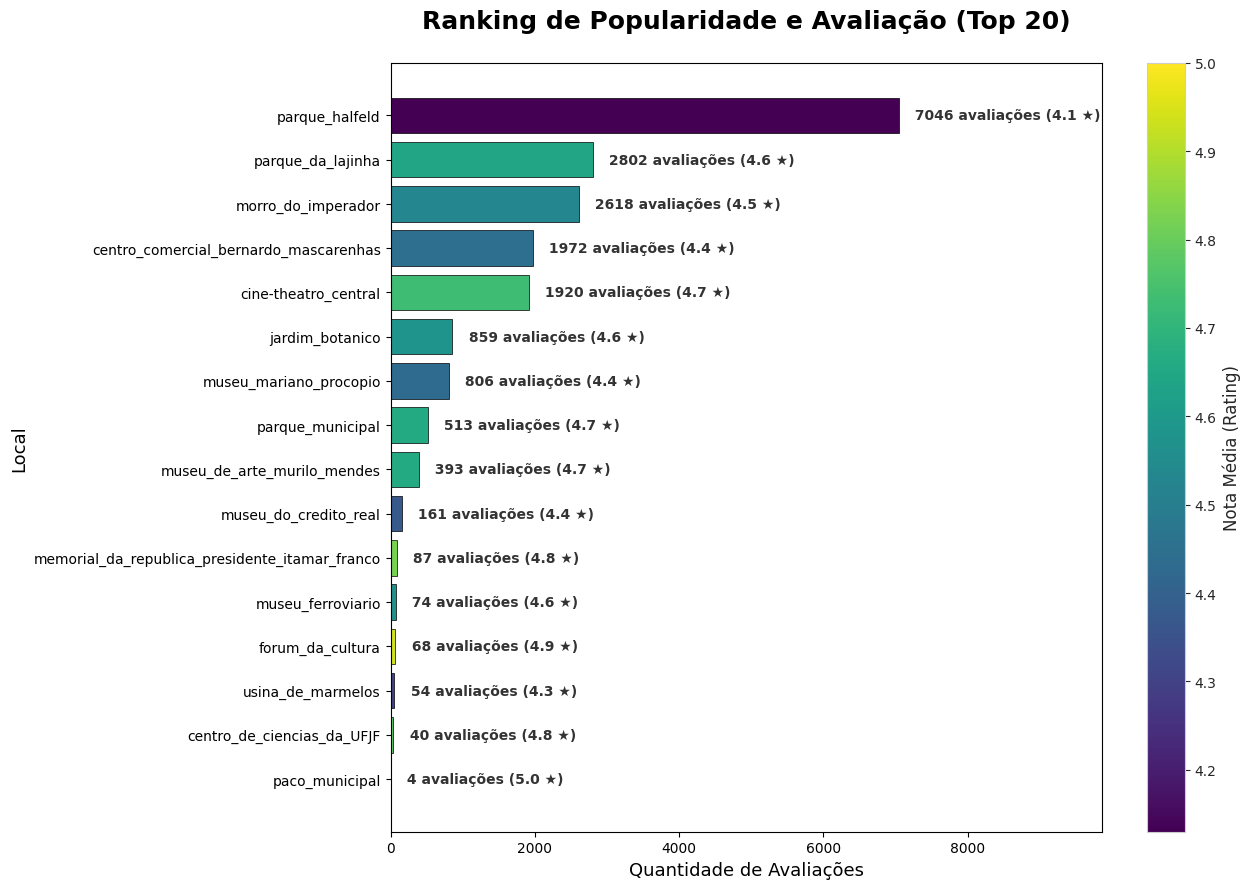

-> Gráfico salvo como imagem em: /content/arquivos_de_trabalho/ranking_top20_locais.png

Gerando gráficos interativos mensais para os locais do Top 20...
-> Sucesso! 16 arquivos HTML salvos em '/content/arquivos_de_trabalho/graficos_tendencia_top20'.


In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import plotly.express as px
from IPython.display import display


#Load

pasta_base = '/content/arquivos_de_trabalho'
os.makedirs(pasta_base, exist_ok=True)

caminho_arquivo = os.path.join(pasta_base, 'base_final_para_nlp.parquet')
df = pd.read_parquet(caminho_arquivo)

#Formatação de data e tipos numéricos
df['isoDate'] = pd.to_datetime(df['isoDate'])
df['likes'] = pd.to_numeric(df['likes'], errors='coerce').fillna(0)

#Mapeamento de completude e engajamento
df['tem_comentario'] = df['snippet'].fillna('').astype(str).str.strip() != ''
df['tem_resposta'] = df['response.snippet'].fillna('').astype(str).str.strip() != ''

estatisticas = df.groupby('origem_lugar').agg(
    total_avaliacoes=('rating', 'count'),
    nota_media=('rating', 'mean'),
    comentarios_escritos=('tem_comentario', 'sum'),
    respostas_proprietario=('tem_resposta', 'sum')
).reset_index()

#Cálculo das taxas percentuais
estatisticas['taxa_completude_comentarios (%)'] = (
    (estatisticas['comentarios_escritos'] / estatisticas['total_avaliacoes']) * 100
).round(2)

estatisticas['taxa_resposta_proprietario (%)'] = (
    (estatisticas['respostas_proprietario'] / estatisticas['total_avaliacoes']) * 100
).round(2)

estatisticas['nota_media'] = estatisticas['nota_media'].round(2)

#Ordenar alfabeticamente para a tabela geral e filtrar Top 20 por volume para os gráficos
estatisticas_ordenadas = estatisticas.sort_values('origem_lugar', ascending=True).reset_index(drop=True)
top_20 = estatisticas.sort_values('total_avaliacoes', ascending=False).head(20).reset_index(drop=True)

print(f"Sucesso! Estatísticas consolidadas de {len(estatisticas_ordenadas)} locais.\n")
display(estatisticas_ordenadas)

#Exportar png

print("Gerando imagem da tabela estatística...")

#Renomear colunas para um cabeçalho mais limpo na imagem
colunas_exibicao = [
    'Local',
    'Total Reviews',
    'Nota Média',
    'Com Texto',
    'Respostas',
    'Completude (%)',
    'Taxa Resp. (%)'
]
df_img = estatisticas_ordenadas.copy()
df_img.columns = colunas_exibicao

#Ajuste dinâmico da altura da figura conforme o número de linhas
altura_fig = max(6, len(df_img) * 0.38 + 1.5)
fig_tab, ax_tab = plt.subplots(figsize=(14, altura_fig))
ax_tab.axis('off')

tabela = ax_tab.table(
    cellText=df_img.values,
    colLabels=df_img.columns,
    cellLoc='center',
    loc='center'
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(10)
tabela.scale(1, 1.45)

#Estilização das células
for (linha, coluna), celula in tabela.get_celld().items():
    celula.set_edgecolor('#d0d7de')
    if linha == 0:
        celula.set_text_props(weight='bold', color='white')
        celula.set_facecolor('#1f4e78')
    else:
        if coluna == 0:
            celula.set_text_props(ha='left')  # Alinha o nome do local à esquerda
        celula.set_facecolor('#f6f8fa' if linha % 2 == 0 else 'white')

tabela.auto_set_column_width(col=list(range(len(df_img.columns))))

plt.title('Resumo Estatístico de Avaliações e Engajamento por Local', fontsize=15, fontweight='bold', pad=15)
caminho_img_tabela = os.path.join(pasta_base, 'tabela_estatisticas_locais.png')
plt.savefig(caminho_img_tabela, dpi=300, bbox_inches='tight', facecolor='white')
plt.close(fig_tab)
print(f"-> Tabela salva como imagem em: {caminho_img_tabela}\n")

#Top20
print("Gerando gráfico de Ranking Geral (Top 20)...")

norm = mcolors.Normalize(vmin=top_20['nota_media'].min(), vmax=top_20['nota_media'].max())
mapper = cm.ScalarMappable(norm=norm, cmap='viridis')
cores_das_barras = [mapper.to_rgba(nota) for nota in top_20['nota_media']]

fig_rank, ax_rank = plt.subplots(figsize=(13, 9))
sns.set_style("whitegrid")

barras = ax_rank.barh(
    top_20['origem_lugar'],
    top_20['total_avaliacoes'],
    color=cores_das_barras,
    edgecolor='black',
    linewidth=0.5
)
ax_rank.invert_yaxis()

labels = [
    f' {int(rev)} avaliações ({nota:.1f} ★)'
    for rev, nota in zip(top_20['total_avaliacoes'], top_20['nota_media'])
]
ax_rank.bar_label(ax_rank.containers[0], labels=labels, padding=8, fontsize=10, fontweight='bold', color='#333')

ax_rank.set_title('Ranking de Popularidade e Avaliação (Top 20)', fontsize=18, pad=25, fontweight='bold')
ax_rank.set_xlabel('Quantidade de Avaliações', fontsize=13)
ax_rank.set_ylabel('Local', fontsize=13)
ax_rank.set_xlim(0, top_20['total_avaliacoes'].max() * 1.4)

cbar = plt.colorbar(mapper, ax=ax_rank)
cbar.set_label('Nota Média (Rating)', fontsize=12)

plt.tight_layout()
caminho_img_ranking = os.path.join(pasta_base, 'ranking_top20_locais.png')
plt.savefig(caminho_img_ranking, dpi=300, bbox_inches='tight')
plt.show()
print(f"-> Gráfico salvo como imagem em: {caminho_img_ranking}\n")

#VISÃO DINÂMICA: GRÁFICOS INTERATIVOS MENSAIS (TOP 20)

print("Gerando gráficos interativos mensais para os locais do Top 20...")
pasta_interativos = os.path.join(pasta_base, 'graficos_tendencia_top20')
os.makedirs(pasta_interativos, exist_ok=True)

for local in top_20['origem_lugar']:
    df_local = df[df['origem_lugar'] == local].copy()
    df_local = df_local.set_index('isoDate').sort_index()

    df_resampled = df_local['rating'].resample('1MS').agg(['mean', 'count']).reset_index()
    df_resampled = df_resampled[df_resampled['count'] > 0].copy()

    media_avaliacoes_local = df_resampled['count'].mean()
    df_resampled['cor_ponto'] = df_resampled['count'].apply(
        lambda x: 'red' if x < media_avaliacoes_local else 'RoyalBlue'
    )

    fig_int = px.line(
        df_resampled,
        x='isoDate',
        y='mean',
        title=f'Desempenho Mensal: {local} <br><sup>Pontos em <span style="color:red">vermelho</span> indicam meses com volume de reviews abaixo da média ({media_avaliacoes_local:.1f})</sup>',
        markers=True,
        labels={'isoDate': 'Período', 'mean': 'Nota Média', 'count': 'Volume de Avaliações'},
        hover_data={
            'isoDate': '|%b %Y',
            'mean': ':.2f',
            'count': True,
            'cor_ponto': False
        }
    )

    fig_int.update_traces(
        line=dict(width=3, color="RoyalBlue", shape='spline'),
        marker=dict(size=10, color=df_resampled['cor_ponto'], line=dict(width=1, color='DarkSlateGrey'))
    )

    fig_int.update_layout(
        yaxis=dict(range=[0.5, 5.5], dtick=1),
        xaxis_title="Período (Meses)",
        yaxis_title="Avaliação Média",
        hovermode="x unified",
        template="plotly_white"
    )

    nome_html = os.path.join(pasta_interativos, f"tendencia_{local.replace(' ', '_').replace('/', '')}.html")
    fig_int.write_html(nome_html)

print(f"-> Sucesso! {len(top_20)} arquivos HTML salvos em '{pasta_interativos}'.")

Agora com todos os dados limpos e prontos para serem utilizados iniciaremos um processo de classificação usando o modelo Ekman baseado em emoções básicas universais definidas por raiva, medo, alegria, tristeza, nojo, surpresa e desprezo.

In [ ]:
import os
import pandas as pd
from transformers import pipeline
from IPython.display import display

#load
pasta_base = '/content/arquivos_de_trabalho'
caminho_arquivo = os.path.join(pasta_base, 'base_final_para_nlp.parquet')
df = pd.read_parquet(caminho_arquivo)

df_teste = df.dropna(subset=['snippet']).copy().reset_index(drop=True)

#Inicializar o modelo
print("Carregando o modelo XLM-RoBERTa-Large-ANLI...")
classificador = pipeline(
    "zero-shot-classification",
    model="vicgalle/xlm-roberta-large-xnli-anli",
    device=0  # Mude para -1 caso esteja rodando em CPU
)

emocoes_ekman = ["alegria", "tristeza", "raiva", "medo", "nojo", "surpresa"]
tamanho_lote = 32

#Limiares
limiar_sent_forte = 0.55   # Para 2 classes (média aleatória = 0.50)
limiar_emocao = 0.30       # Para 6 classes no Softmax (média aleatória = 0.166)


#Classificaçao dos sentimento + rating

print(f"Classificando sentimentos em lotes (batch_size={tamanho_lote})...")
textos_todos = df_teste['snippet'].tolist()

res_sentimentos = classificador(
    textos_todos,
    candidate_labels=["positivo", "negativo"],
    hypothesis_template="Esta avaliação expressa um sentimento {}.",
    batch_size=tamanho_lote,
    truncation=True
)

sentimentos_finais = []
confiancas_sent = []

tem_rating = 'rating' in df_teste.columns
ratings = pd.to_numeric(df_teste['rating'], errors='coerce').fillna(3).tolist() if tem_rating else [3] * len(df_teste)

for res, nota in zip(res_sentimentos, ratings):
    label_topo = res['labels'][0]
    score_topo = res['scores'][0]

    # Se o modelo tem confiança clara no texto, mantém a decisão do classificador
    if score_topo >= limiar_sent_forte:
        sentimentos_finais.append(label_topo)
        confiancas_sent.append(round(score_topo, 4))
    else:
        # Desempate usando rating para textos curtos/ambíguos
        if nota >= 4:
            sentimentos_finais.append("positivo")
            confiancas_sent.append(round(max(score_topo, 0.55), 4))
        elif nota <= 2:
            sentimentos_finais.append("negativo")
            confiancas_sent.append(round(max(score_topo, 0.55), 4))
        else:
            sentimentos_finais.append("neutro")
            confiancas_sent.append(round(score_topo, 4))

df_teste['sentimento'] = sentimentos_finais
df_teste['confianca_sent'] = confiancas_sent

# Inicializar colunas de emoção
df_teste['emocao'] = "inconclusivo"
df_teste['confianca_emocao'] = 0.0


# Classificaçao das emoçoes em lotes

mascara_elegiveis = df_teste['sentimento'] != "neutro"
indices_elegiveis = df_teste[mascara_elegiveis].index
textos_elegiveis = df_teste.loc[indices_elegiveis, 'snippet'].tolist()

if textos_elegiveis:
    print(f"Classificando emoções para {len(textos_elegiveis)} textos elegíveis em lotes...")
    res_emocoes = classificador(
        textos_elegiveis,
        candidate_labels=emocoes_ekman,
        hypothesis_template="Esta avaliação transmite a emoção de {}.",
        batch_size=tamanho_lote,
        multi_label=False,  # Soma 1.0 entre as 6 emoções, mas com limiar calibrado (0.30)
        truncation=True
    )

    emocoes_finais = []
    scores_finais = []

    for res in res_emocoes:
        emocao_topo = res['labels'][0]
        score_topo = res['scores'][0]
        segundo_score = res['scores'][1]

        # Aceita a emoção se passar de 0.30
        # OU se tiver vantagem sobre a 2ª (margem >= 0.08)
        if score_topo >= limiar_emocao or (score_topo >= 0.24 and (score_topo - segundo_score) >= 0.08):
            emocoes_finais.append(emocao_topo)
        else:
            emocoes_finais.append("inconclusivo")
        scores_finais.append(round(score_topo, 4))

    df_teste.loc[indices_elegiveis, 'emocao'] = emocoes_finais
    df_teste.loc[indices_elegiveis, 'confianca_emocao'] = scores_finais

#Resumo e estatisticas
print("\n--- Resumo da Nova Distribuição de Sentimentos ---")
print(df_teste['sentimento'].value_counts(dropna=False).to_frame(name='total'))

print("\n--- Resumo da Nova Distribuição de Emoções (Ekman) ---")
resumo_emocoes = df_teste['emocao'].value_counts(dropna=False).to_frame(name='total')
resumo_emocoes['percentual (%)'] = ((resumo_emocoes['total'] / len(df_teste)) * 100).round(2)
display(resumo_emocoes)

print("\n--- Amostra da Classificação ---")
df_final = df_teste[['snippet', 'rating', 'sentimento', 'confianca_sent', 'emocao', 'confianca_emocao']]
display(df_final.head(15))

caminho_saida_parquet = os.path.join(pasta_base, 'base_final_classificada.parquet')
caminho_saida_csv = os.path.join(pasta_base, 'classificacao_ekman_anli.csv')

df_teste.to_parquet(caminho_saida_parquet, index=False, engine='pyarrow')
df_teste.to_csv(caminho_saida_csv, index=False, encoding='utf-8-sig')

print(f"\n-> Arquivo Parquet salvo em: {caminho_saida_parquet}")
print(f"-> Arquivo CSV salvo em: {caminho_saida_csv}")

Carregando o modelo XLM-RoBERTa-Large-ANLI...


config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

... (3 outputs left out)

,total,percentual (%)
emocao,,
alegria,12421,63.97
surpresa,3780,19.47
nojo,1394,7.18
tristeza,699,3.60
inconclusivo,590,3.04
medo,517,2.66
raiva,16,0.08



--- Amostra da Classificação ---


,snippet,rating,sentimento,confianca_sent,emocao,confianca_emocao
0,Museu maravilhoso !,5,positivo,0.9996,alegria,0.7033
1,"Adorei é aberto bom para brincar, eu sou uma c...",5,positivo,0.9996,alegria,0.6857
2,Lugar incrível de contato com a natureza e con...,5,positivo,0.9996,alegria,0.7058
3,Muito bom,5,positivo,0.9997,alegria,0.7844
4,Ótimo para caminhar com presença da natureza,5,positivo,0.9997,alegria,0.8029
5,Uma excelente opção de lazer cultural. Acervo ...,5,positivo,0.9995,alegria,0.6148
6,"Muito bonito, com um acervo magnífico",5,positivo,0.9997,alegria,0.8274
7,Museu multi temático com um rico acervo: utens...,5,positivo,0.9476,inconclusivo,0.2606
8,Edificante.,5,positivo,0.9997,surpresa,0.7844
9,Very nicely laud out and preserved home and mu...,5,positivo,0.9996,alegria,0.7836



-> Arquivo Parquet salvo em: /content/arquivos_de_trabalho/base_final_classificada.parquet
-> Arquivo CSV salvo em: /content/arquivos_de_trabalho/classificacao_ekman_anli.csv


Com os dados filtrados e totalmente classificados faremos analises temporais sobre eles com objetivo de entender como cada local se comporta através do review das pessoas

In [ ]:
import os
import pandas as pd
import plotly.express as px
from IPython.display import display
import zipfile

#load
caminho_classificado = '/content/arquivos_de_trabalho/base_final_classificada.parquet'
df_stats = pd.read_parquet(caminho_classificado)

coluna_data = 'isoDate'
coluna_local = 'origem_lugar'

df_stats[coluna_data] = pd.to_datetime(df_stats[coluna_data])

#agrupamento por Ano-Mês
df_stats['ano_mes_dt'] = df_stats[coluna_data].dt.to_period('M').dt.to_timestamp()

# --- ESTATÍSTICA 1: Visão Geral de Emoções por Local ---
print("### Distribuição Geral de Emoções por Local (%) ###")
estatisticas_local = pd.crosstab(df_stats[coluna_local], df_stats['emocao'], normalize='index') * 100
display(estatisticas_local.round(2).astype(str) + '%')

# Obter os top 3 locais com mais dados para gerar os gráficos
top_locais = df_stats[coluna_local].value_counts().index.tolist()

# =====================================================================
# Criando uma pasta temporária e a lista para armazenar os caminhos dos arquivos
pasta_temp = 'temp_html_files'
os.makedirs(pasta_temp, exist_ok=True)
arquivos_html_gerados = []
# =====================================================================

# --- ESTATÍSTICA 2: Evolução Temporal das Emoções ---
print("\n### Gerando Gráficos Interativos de Emoções... ###")
evolucao_temporal = df_stats.groupby([coluna_local, 'ano_mes_dt', 'emocao']).size().reset_index(name='contagem')

for local in top_locais:
    df_local = evolucao_temporal[evolucao_temporal[coluna_local] == local]

    fig_emocoes = px.line(
        df_local,
        x='ano_mes_dt',
        y='contagem',
        color='emocao',
        markers=True,
        title=f'Evolução Interativa das Emoções - {local}',
        labels={'ano_mes_dt': 'Data', 'contagem': 'Volume de Menções', 'emocao': 'Emoção (Ekman)'}
    )

    fig_emocoes.show()

    # Salvar em arquivo HTML temporário e adicionar à lista
    nome_limpo = str(local).replace(" ", "_").replace("/", "_")
    nome_arquivo_emocao = os.path.join(pasta_temp, f'evolucao_emocoes_{nome_limpo}.html')
    fig_emocoes.write_html(nome_arquivo_emocao)
    arquivos_html_gerados.append(nome_arquivo_emocao)

# --- ESTATÍSTICA 3: Emoção Predominante por Local em Cada Período ---
print("\n### Análise Condensada: Emoção Predominante por Período e Local ###")
emocao_predominante = evolucao_temporal.sort_values('contagem', ascending=False).drop_duplicates([coluna_local, 'ano_mes_dt'])
emocao_predominante['periodo'] = emocao_predominante['ano_mes_dt'].dt.strftime('%Y-%m')
tabela_predominante = emocao_predominante.pivot(index='periodo', columns=coluna_local, values='emocao')
display(tabela_predominante[top_locais].fillna('-'))

# --- ESTATÍSTICA 4: Sentimento por Local (Positivo vs Negativo) ---
print("\n### Evolução do Sentimento Separada por Local ###")
if 'sentimento' in df_stats.columns:
    df_stats['ano_mes_str'] = df_stats['ano_mes_dt'].dt.strftime('%Y-%m')
    tabela_sentimento_local = df_stats.groupby([coluna_local, 'ano_mes_str', 'sentimento']).size().unstack(fill_value=0)
    display(tabela_sentimento_local.loc[top_locais])

    sentimento_temporal = df_stats.groupby([coluna_local, 'ano_mes_dt', 'sentimento']).size().reset_index(name='contagem')

    for local in top_locais:
        df_sent_local = sentimento_temporal[sentimento_temporal[coluna_local] == local]

        fig_sent = px.bar(
            df_sent_local,
            x='ano_mes_dt',
            y='contagem',
            color='sentimento',
            barmode='group',
            color_discrete_map={"Positivo": "green", "Negativo": "red", "Neutro": "gray"},
            title=f'Evolução do Sentimento (Pos/Neg) - {local}',
            labels={'ano_mes_dt': 'Data', 'contagem': 'Volume', 'sentimento': 'Sentimento'}
        )

        fig_sent.show()

        # Salvar em arquivo HTML temporário e adicionar à lista
        nome_limpo = str(local).replace(" ", "_").replace("/", "_")
        nome_arquivo_sent = os.path.join(pasta_temp, f'evolucao_sentimento_{nome_limpo}.html')
        fig_sent.write_html(nome_arquivo_sent)
        arquivos_html_gerados.append(nome_arquivo_sent)
else:
    print("A coluna 'sentimento' não foi encontrada na base de dados.")

# =====================================================================
# GERAR E BAIXAR O ARQUIVO ZIP
print("\n### Compactando e Baixando os Gráficos... ###")
zip_filename = 'graficos_interativos_locais.zip'

# Cria o arquivo ZIP e adiciona todos os HTMLs gerados
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in arquivos_html_gerados:
        zipf.write(file, os.path.basename(file)) # os.path.basename evita que a pasta 'temp_html_files' seja criada dentro do zip

print(f"Pronto! O arquivo {zip_filename} foi criado.")

# Limpeza: Apaga a pasta temporária e os HTMLs soltos (opcional)
import shutil
shutil.rmtree(pasta_temp)


### Distribuição Geral de Emoções por Local (%) ###


/tmp/ipykernel_1017/965761851.py:17: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_stats['ano_mes_dt'] = df_stats[coluna_data].dt.to_period('M').dt.to_timestamp()


emocao,alegria,inconclusivo,medo,nojo,raiva,surpresa,tristeza
origem_lugar,,,,,,,
centro_comercial_bernardo_mascarenhas,57.66%,2.43%,1.06%,8.06%,0.05%,28.09%,2.64%
centro_de_ciencias_da_UFJF,60.0%,0.0%,0.0%,5.0%,0.0%,32.5%,2.5%
cine-theatro_central,68.44%,1.3%,0.83%,6.15%,0.0%,21.82%,1.46%
forum_da_cultura,75.0%,0.0%,0.0%,2.94%,0.0%,22.06%,0.0%
jardim_botanico,74.97%,2.21%,0.81%,2.91%,0.0%,17.46%,1.63%
memorial_da_republica_presidente_itamar_franco,65.52%,3.45%,0.0%,2.3%,0.0%,27.59%,1.15%
morro_do_imperador,69.6%,1.72%,1.41%,4.85%,0.0%,18.33%,4.09%
museu_de_arte_murilo_mendes,63.36%,1.53%,1.02%,4.83%,0.0%,27.74%,1.53%
museu_do_credito_real,47.2%,5.59%,1.24%,11.18%,0.62%,30.43%,3.73%



### Gerando Gráficos Interativos de Emoções... ###



### Análise Condensada: Emoção Predominante por Período e Local ###


origem_lugar,parque_halfeld,parque_da_lajinha,morro_do_imperador,centro_comercial_bernardo_mascarenhas,cine-theatro_central,jardim_botanico,museu_mariano_procopio,parque_municipal,museu_de_arte_murilo_mendes,museu_do_credito_real,memorial_da_republica_presidente_itamar_franco,museu_ferroviario,forum_da_cultura,usina_de_marmelos,centro_de_ciencias_da_UFJF,paco_municipal
periodo,,,,,,,,,,,,,,,,
2012-05,-,-,alegria,-,-,-,surpresa,-,-,-,-,-,-,-,-,-
2012-08,-,-,-,-,alegria,-,-,-,-,-,-,-,-,-,-,-
2012-10,-,-,-,-,-,-,alegria,-,-,-,-,-,-,-,-,-
2013-02,-,-,alegria,-,-,-,-,-,-,-,-,-,-,-,-,-
2013-09,-,-,-,-,-,-,surpresa,-,-,-,-,-,-,-,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12,alegria,alegria,alegria,alegria,alegria,alegria,alegria,alegria,alegria,alegria,-,alegria,-,surpresa,-,-
2026-01,alegria,alegria,alegria,-,alegria,alegria,alegria,alegria,alegria,-,alegria,alegria,alegria,-,-,-
2026-02,alegria,alegria,alegria,surpresa,alegria,alegria,alegria,alegria,alegria,-,alegria,alegria,alegria,-,-,-



### Evolução do Sentimento Separada por Local ###


sentimento                              negativo  neutro  positivo
origem_lugar               ano_mes_str                            
parque_halfeld             2016-10             1       0         5
                           2016-11             0       0         6
                           2016-12             1       0        15
                           2017-01             9       0        22
                           2017-02             7       0        24
...                                          ...     ...       ...
centro_de_ciencias_da_UFJF 2025-08             0       0         1
paco_municipal             2024-01             0       0         1
                           2024-09             0       0         1
                           2024-11             0       0         1
                           2025-08             0       0         1

[1190 rows x 3 columns]


### Compactando e Baixando os Gráficos... ###
Pronto! O arquivo graficos_interativos_locais.zip foi criado.


In [ ]:
import os
import pandas as pd
import plotly.express as px
from IPython.display import display
import zipfile

#load
caminho_classificado = '/content/arquivos_de_trabalho/base_classificada_ekman.parquet'
df_stats = pd.read_parquet(caminho_classificado)

coluna_data = 'isoDate'
coluna_local = 'origem_lugar'

df_stats[coluna_data] = pd.to_datetime(df_stats[coluna_data])

#agrupamento por Ano-Mês
df_stats['ano_mes_dt'] = df_stats[coluna_data].dt.to_period('M').dt.to_timestamp()

# --- ESTATÍSTICA 1: Visão Geral de Emoções por Local ---
print("### Distribuição Geral de Emoções por Local (%) ###")
estatisticas_local = pd.crosstab(df_stats[coluna_local], df_stats['emocao'], normalize='index') * 100
display(estatisticas_local.round(2).astype(str) + '%')

# Obter os top 3 locais com mais dados para gerar os gráficos
top_locais = df_stats[coluna_local].value_counts().index.tolist()

# =====================================================================
# Criando uma pasta temporária e a lista para armazenar os caminhos dos arquivos
pasta_temp = 'temp_html_files'
os.makedirs(pasta_temp, exist_ok=True)
arquivos_html_gerados = []
# =====================================================================

# --- ESTATÍSTICA 2: Evolução Temporal das Emoções ---
print("\n### Gerando Gráficos Interativos de Emoções... ###")
evolucao_temporal = df_stats.groupby([coluna_local, 'ano_mes_dt', 'emocao']).size().reset_index(name='contagem')

for local in top_locais:
    df_local = evolucao_temporal[evolucao_temporal[coluna_local] == local]

    fig_emocoes = px.line(
        df_local,
        x='ano_mes_dt',
        y='contagem',
        color='emocao',
        markers=True,
        title=f'Evolução Interativa das Emoções - {local}',
        labels={'ano_mes_dt': 'Data', 'contagem': 'Volume de Menções', 'emocao': 'Emoção (Ekman)'}
    )

    fig_emocoes.show()

    # Salvar em arquivo HTML temporário e adicionar à lista
    nome_limpo = str(local).replace(" ", "_").replace("/", "_")
    nome_arquivo_emocao = os.path.join(pasta_temp, f'evolucao_emocoes_{nome_limpo}.html')
    fig_emocoes.write_html(nome_arquivo_emocao)
    arquivos_html_gerados.append(nome_arquivo_emocao)

# --- ESTATÍSTICA 3: Emoção Predominante por Local em Cada Período ---
print("\n### Análise Condensada: Emoção Predominante por Período e Local ###")
emocao_predominante = evolucao_temporal.sort_values('contagem', ascending=False).drop_duplicates([coluna_local, 'ano_mes_dt'])
emocao_predominante['periodo'] = emocao_predominante['ano_mes_dt'].dt.strftime('%Y-%m')
tabela_predominante = emocao_predominante.pivot(index='periodo', columns=coluna_local, values='emocao')
display(tabela_predominante[top_locais].fillna('-'))

# --- ESTATÍSTICA 4: Sentimento por Local (Positivo vs Negativo) ---
print("\n### Evolução do Sentimento Separada por Local ###")
if 'sentimento' in df_stats.columns:
    df_stats['ano_mes_str'] = df_stats['ano_mes_dt'].dt.strftime('%Y-%m')
    tabela_sentimento_local = df_stats.groupby([coluna_local, 'ano_mes_str', 'sentimento']).size().unstack(fill_value=0)
    display(tabela_sentimento_local.loc[top_locais])

    sentimento_temporal = df_stats.groupby([coluna_local, 'ano_mes_dt', 'sentimento']).size().reset_index(name='contagem')

    for local in top_locais:
        df_sent_local = sentimento_temporal[sentimento_temporal[coluna_local] == local]

        fig_sent = px.bar(
            df_sent_local,
            x='ano_mes_dt',
            y='contagem',
            color='sentimento',
            barmode='group',
            color_discrete_map={"Positivo": "green", "Negativo": "red", "Neutro": "gray"},
            title=f'Evolução do Sentimento (Pos/Neg) - {local}',
            labels={'ano_mes_dt': 'Data', 'contagem': 'Volume', 'sentimento': 'Sentimento'}
        )

        fig_sent.show()

        # Salvar em arquivo HTML temporário e adicionar à lista
        nome_limpo = str(local).replace(" ", "_").replace("/", "_")
        nome_arquivo_sent = os.path.join(pasta_temp, f'evolucao_sentimento_{nome_limpo}.html')
        fig_sent.write_html(nome_arquivo_sent)
        arquivos_html_gerados.append(nome_arquivo_sent)
else:
    print("A coluna 'sentimento' não foi encontrada na base de dados.")

# =====================================================================
# GERAR E BAIXAR O ARQUIVO ZIP
print("\n### Compactando e Baixando os Gráficos... ###")
zip_filename = 'graficos_interativos_locais.zip'

# Cria o arquivo ZIP e adiciona todos os HTMLs gerados
with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in arquivos_html_gerados:
        zipf.write(file, os.path.basename(file)) # os.path.basename evita que a pasta 'temp_html_files' seja criada dentro do zip

print(f"Pronto! O arquivo {zip_filename} foi criado.")

# Limpeza: Apaga a pasta temporária e os HTMLs soltos (opcional)
import shutil
shutil.rmtree(pasta_temp)


### Distribuição Geral de Emoções por Local (%) ###


/tmp/ipykernel_1017/559328448.py:17: UserWarning:

Converting to PeriodArray/Index representation will drop timezone information.



emocao,alegria,inconclusivo,medo,nojo,raiva,surpresa,tristeza
origem_lugar,,,,,,,
centro_comercial_bernardo_mascarenhas,55.17%,20.89%,0.05%,0.05%,0.05%,20.08%,3.7%
centro_de_ciencias_da_UFJF,65.0%,10.0%,2.5%,0.0%,0.0%,22.5%,0.0%
cine-theatro_central,48.96%,13.96%,0.0%,0.0%,0.0%,35.21%,1.88%
forum_da_cultura,70.59%,5.88%,0.0%,0.0%,0.0%,23.53%,0.0%
jardim_botanico,64.96%,12.34%,0.0%,0.12%,0.0%,21.19%,1.4%
memorial_da_republica_presidente_itamar_franco,59.77%,6.9%,0.0%,0.0%,0.0%,32.18%,1.15%
morro_do_imperador,43.77%,16.35%,0.11%,0.0%,0.0%,37.2%,2.56%
museu_de_arte_murilo_mendes,56.49%,10.69%,0.0%,0.51%,0.0%,29.26%,3.05%
museu_do_credito_real,37.89%,27.95%,0.0%,0.0%,0.0%,29.19%,4.97%



### Gerando Gráficos Interativos de Emoções... ###



### Análise Condensada: Emoção Predominante por Período e Local ###


origem_lugar,parque_halfeld,parque_da_lajinha,morro_do_imperador,centro_comercial_bernardo_mascarenhas,cine-theatro_central,jardim_botanico,museu_mariano_procopio,parque_municipal,museu_de_arte_murilo_mendes,museu_do_credito_real,memorial_da_republica_presidente_itamar_franco,museu_ferroviario,forum_da_cultura,usina_de_marmelos,centro_de_ciencias_da_UFJF,paco_municipal
periodo,,,,,,,,,,,,,,,,
2012-05,-,-,alegria,-,-,-,inconclusivo,-,-,-,-,-,-,-,-,-
2012-08,-,-,-,-,surpresa,-,-,-,-,-,-,-,-,-,-,-
2012-10,-,-,-,-,-,-,surpresa,-,-,-,-,-,-,-,-,-
2013-02,-,-,alegria,-,-,-,-,-,-,-,-,-,-,-,-,-
2013-09,-,-,-,-,-,-,alegria,-,-,-,-,-,-,-,-,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12,alegria,alegria,alegria,alegria,alegria,inconclusivo,alegria,inconclusivo,alegria,alegria,-,alegria,-,inconclusivo,-,-
2026-01,alegria,alegria,alegria,-,alegria,alegria,alegria,alegria,alegria,-,alegria,alegria,surpresa,-,-,-
2026-02,alegria,alegria,alegria,inconclusivo,alegria,alegria,surpresa,alegria,alegria,-,alegria,alegria,alegria,-,-,-



### Evolução do Sentimento Separada por Local ###


sentimento                              inconclusivo  negativo  neutro  \
origem_lugar               ano_mes_str                                   
parque_halfeld             2016-10                 0         2       0   
                           2016-11                 0         0       0   
                           2016-12                 2         1       0   
                           2017-01                 2         8       0   
                           2017-02                 2         7       0   
...                                              ...       ...     ...   
centro_de_ciencias_da_UFJF 2025-08                 0         0       0   
paco_municipal             2024-01                 0         0       0   
                           2024-09                 0         0       0   
                           2024-11                 0         0       0   
                           2025-08                 0         0       0   

sentimento                              positivo  
origem_lugar               ano_mes_str            
parque_halfeld             2016-10             4  
                           2016-11             6  
                           2016-12            13  
                           2017-01            21  
                           2017-02            22  
...                                          ...  
centro_de_ciencias_da_UFJF 2025-08             1  
paco_municipal             2024-01             1  
                           2024-09             1  
                           2024-11             1  
                           2025-08             1  

[1190 rows x 4 columns]


### Compactando e Baixando os Gráficos... ###
Pronto! O arquivo graficos_interativos_locais.zip foi criado.


Além de uma análise no tempo tambem podemos ter a analise espacial visualizando como os locais se comportam inclusive encontrando os impactor da pandemia de 2020.


In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import ipywidgets as widgets
from IPython.display import display, clear_output


#Dicionário de Coordenadas de JF

coordenadas_jf = {
    "centro_comercial_bernardo_mascarenhas": [-21.76132, -43.34440],
    "centro_de_ciencias_da_UFJF": [-21.77673, -43.37121],
    "cine-theatro_central": [-21.76070, -43.34863],
    "forum_da_cultura": [-21.763340, -43.350893],
    "jardim_botanico": [-21.737763, -43.369391],
    "memorial_da_republica_presidente_itamar_franco": [-21.756091, -43.351811],
    "morro_do_imperador": [-21.763387, -43.358111],
    "museu_de_arte_murilo_mendes": [-21.756245, -43.352128],
    "museu_do_credito_real": [-21.760515, -43.346261],
    "museu_ferroviario": [-21.758910, -43.343603],
    "museu_mariano_procopio": [-21.746030, -43.360038],
    "paco_municipal": [-21.761462, -43.349840],
    "parque_da_lajinha": [-21.792971, -43.367222],
    "parque_halfeld": [-21.76185, -43.350315],
    "parque_municipal": [-21.793075, -43.397996],
    "usina_de_marmelos": [-21.786953, -43.308470]
}


#load

df = pd.read_parquet('/content/base_final_classificada.parquet')

coluna_local = 'origem_lugar'
coluna_emocao = 'emocao'
coluna_data = 'isoDate'

# Conversão de datas e limpeza
df[coluna_data] = pd.to_datetime(df[coluna_data], errors='coerce')
df = df.dropna(subset=[coluna_data, coluna_local, coluna_emocao])

# Criação das colunas para os três níveis de tempo
df['Mes'] = df[coluna_data].dt.to_period('M').astype(str)
df['Ano'] = df[coluna_data].dt.year.astype(str)
# Lógica para Semestre (Ex: 2026-S1 ou 2026-S2)
df['Semestre'] = df[coluna_data].dt.year.astype(str) + "-S" + np.where(df[coluna_data].dt.month <= 6, '1', '2')

cores_ekman = {
    "alegria": "#2ecc71", "tristeza": "#3498db", "raiva": "#e74c3c",
    "medo": "#9b59b6", "nojo": "#27ae60", "surpresa": "#f1c40f", "inconclusivo": "#95a5a6"
}

#Geraçao do Mapa

def gerar_mapa(agrupamento_temporal):
    # Agrupa com base na escolha do usuário
    df_contagem = df.groupby([coluna_local, agrupamento_temporal, coluna_emocao]).size().reset_index(name='volume_reviews')

    # Encontra a emoção dominante
    idx_max = df_contagem.groupby([coluna_local, agrupamento_temporal])['volume_reviews'].idxmax()
    df_animacao = df_contagem.loc[idx_max].copy()

    # Aplica coordenadas
    df_animacao['lat'] = df_animacao[coluna_local].map(lambda x: coordenadas_jf.get(x, [None, None])[0])
    df_animacao['lon'] = df_animacao[coluna_local].map(lambda x: coordenadas_jf.get(x, [None, None])[1])
    df_animacao = df_animacao.dropna(subset=['lat', 'lon'])

    # Ordena cronologicamente
    df_animacao = df_animacao.sort_values(agrupamento_temporal)
    df_animacao['Local'] = df_animacao[coluna_local].str.replace("_", " ").str.title()

    # Criação do Gráfico
    fig = px.scatter_mapbox(
        df_animacao, lat="lat", lon="lon",
        color=coluna_emocao, size="volume_reviews",
        animation_frame=agrupamento_temporal,
        hover_name="Local",
        hover_data={"lat": False, "lon": False, agrupamento_temporal: False, "volume_reviews": True},
        color_discrete_map=cores_ekman,
        size_max=35, zoom=12.5, center={"lat": -21.7600, "lon": -43.3500},
        title=f"Análise de Emoções em Juiz de Fora (Agrupamento: {agrupamento_temporal})"
    )

    # Injeção do mapa base público
    fig.update_layout(
        mapbox_style="white-bg",
        mapbox_layers=[{
            "below": 'traces', "sourcetype": "raster", "sourceattribution": "Esri",
            "source": ["https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"]
        }],
        margin={"r":0, "t":40, "l":0, "b":0}
    )

    fig.show()

    # Salva um backup em HTML com a visão atual
    fig.write_html(f"/content/mapa_emocoes_{agrupamento_temporal}.html")
    print(f"\n=> Mapa salvo como: /content/mapa_emocoes_{agrupamento_temporal}.html")


# 4. Interface Interativ
dropdown = widgets.Dropdown(
    options=[('Mensal', 'Mes'), ('Semestral', 'Semestre'), ('Anual', 'Ano')],
    value='Mes',
    description='Agrupamento:',
)

saida_mapa = widgets.Output()

def ao_mudar_dropdown(change):
    with saida_mapa:
        clear_output(wait=True)
        gerar_mapa(change.new)

dropdown.observe(ao_mudar_dropdown, names='value')

display(dropdown)
with saida_mapa:
    gerar_mapa(dropdown.value)
display(saida_mapa)

/tmp/ipykernel_1969/630392231.py:43: UserWarning:

Converting to PeriodArray/Index representation will drop timezone information.



Dropdown(description='Agrupamento:', options=(('Mensal', 'Mes'), ('Semestral', 'Semestre'), ('Anual', 'Ano')),…

Output()

In [ ]:
import pandas as pd
import numpy as np
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Dicionário de Coordenadas de JF
coordenadas_jf = {
    "centro_comercial_bernardo_mascarenhas": [-21.76132, -43.34440],
    "centro_de_ciencias_da_UFJF": [-21.77673, -43.37121],
    "cine-theatro_central": [-21.76070, -43.34863],
    "forum_da_cultura": [-21.763340, -43.350893],
    "jardim_botanico": [-21.737763, -43.369391],
    "memorial_da_republica_presidente_itamar_franco": [-21.756091, -43.351811],
    "morro_do_imperador": [-21.763387, -43.358111],
    "museu_de_arte_murilo_mendes": [-21.756245, -43.352128],
    "museu_do_credito_real": [-21.760515, -43.346261],
    "museu_ferroviario": [-21.758910, -43.343603],
    "museu_mariano_procopio": [-21.746030, -43.360038],
    "paco_municipal": [-21.761462, -43.349840],
    "parque_da_lajinha": [-21.792971, -43.367222],
    "parque_halfeld": [-21.76185, -43.350315],
    "parque_municipal": [-21.793075, -43.397996],
    "usina_de_marmelos": [-21.786953, -43.308470]
}

cores_ekman = {
    "alegria": "#2ecc71", "tristeza": "#3498db", "raiva": "#e74c3c",
    "medo": "#9b59b6", "nojo": "#27ae60", "surpresa": "#f1c40f", "inconclusivo": "#95a5a6"
}

# 1. Carregamento e Preparação dos Dados
df = pd.read_parquet('/content/base_final_classificada.parquet')

coluna_local = 'origem_lugar'
coluna_emocao = 'emocao'
coluna_data = 'isoDate'

df[coluna_data] = pd.to_datetime(df[coluna_data], errors='coerce')
df = df.dropna(subset=[coluna_data, coluna_local, coluna_emocao])

# Isola 2020 e cria coluna com o número do mês
df_2020 = df[df[coluna_data].dt.year == 2020].copy()
df_2020['Mes_Num'] = df_2020[coluna_data].dt.month

# Filtra o primeiro semestre (1 a 6)
df_semestre = df_2020[df_2020['Mes_Num'].isin([1, 2, 3, 4, 5, 6])].copy()

# 2. Agrupamento e identificação da emoção dominante
df_contagem = df_semestre.groupby(['Mes_Num', coluna_local, coluna_emocao]).size().reset_index(name='volume_reviews')
idx_max = df_contagem.groupby(['Mes_Num', coluna_local])['volume_reviews'].idxmax()
df_plot = df_contagem.loc[idx_max].copy()

# Injeção de coordenadas
df_plot['lat'] = df_plot[coluna_local].map(lambda x: coordenadas_jf.get(x, [None, None])[0])
df_plot['lon'] = df_plot[coluna_local].map(lambda x: coordenadas_jf.get(x, [None, None])[1])
df_plot = df_plot.dropna(subset=['lat', 'lon'])
df_plot['Local'] = df_plot[coluna_local].str.replace("_", " ").str.title()

# =====================================================================
# NOVA LÓGICA DE ESCALA: Suavização por Raiz Quadrada e Mapeamento Min-Max
# =====================================================================
TAMANHO_MIN_PIXELS = 12
TAMANHO_MAX_PIXELS = 45

# Aplica raiz quadrada no volume para suavizar outliers
volumes_suavizados = np.sqrt(df_plot['volume_reviews'])

# Interpola matematicamente para garantir que a menor bolha terá 12px e a maior 45px
df_plot['tamanho_bolha'] = np.interp(
    volumes_suavizados,
    (volumes_suavizados.min(), volumes_suavizados.max()),
    (TAMANHO_MIN_PIXELS, TAMANHO_MAX_PIXELS)
)
# =====================================================================

# 3. Configuração do Painel (Subplots 2x3)
nomes_meses = {1: "Janeiro", 2: "Fevereiro", 3: "Março", 4: "Abril", 5: "Maio", 6: "Junho"}

fig = make_subplots(
    rows=2, cols=3,
    specs=[[{"type": "mapbox"}, {"type": "mapbox"}, {"type": "mapbox"}],
           [{"type": "mapbox"}, {"type": "mapbox"}, {"type": "mapbox"}]],
    subplot_titles=[f"{nomes_meses[m]} / 2020" for m in range(1, 7)],
    vertical_spacing=0.08,
    horizontal_spacing=0.05
)

emocoes_na_legenda = set()

# 4. Construção dos 6 Mapas
for i, mes in enumerate(range(1, 7)):
    row = (i // 3) + 1
    col = (i % 3) + 1

    df_mes = df_plot[df_plot['Mes_Num'] == mes]

    for emocao in df_mes[coluna_emocao].unique():
        df_emocao = df_mes[df_mes[coluna_emocao] == emocao]

        mostrar_legenda = emocao not in emocoes_na_legenda
        emocoes_na_legenda.add(emocao)

        fig.add_trace(go.Scattermapbox(
            lat=df_emocao['lat'],
            lon=df_emocao['lon'],
            mode='markers',
            marker=dict(
                size=df_emocao['tamanho_bolha'], # Usando a nova coluna em pixels
                sizemode='diameter', # Garante que o Plotly leia o valor como diâmetro exato
                color=cores_ekman.get(emocao, "#95a5a6"),
                opacity=0.85 # Transparência para não esconder bolhas sobrepostas
            ),
            name=emocao.title(),
            text=df_emocao['Local'] + "<br>Volume Real: " + df_emocao['volume_reviews'].astype(str),
            hoverinfo='text',
            showlegend=mostrar_legenda
        ), row=row, col=col)

# 5. Configuração Visual dos Mapas Base
config_mapbox = dict(
    style="white-bg",
    center=dict(lat=-21.7600, lon=-43.3500),
    zoom=11.2,
    layers=[{
        "below": 'traces', "sourcetype": "raster", "sourceattribution": "Esri",
        "source": ["https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"]
    }]
)

fig.update_layout(
    mapbox=config_mapbox,
    mapbox2=config_mapbox,
    mapbox3=config_mapbox,
    mapbox4=config_mapbox,
    mapbox5=config_mapbox,
    mapbox6=config_mapbox,
    title_text="Evolução das Emoções em Juiz de Fora (1º Semestre de 2020)",
    title_x=0.5,
    height=850,
    width=1350,
    margin={"r":10, "t":90, "l":10, "b":10},
    legend=dict(title="Emoção Dominante", orientation="h", yanchor="bottom", y=-0.1, xanchor="center", x=0.5)
)

fig.show()

fig.write_html("/content/painel_emocoes_1_semestre_2020.html")
print("\n=> Painel integrado salvo como: /content/painel_emocoes_1_semestre_2020.html")


=> Painel integrado salvo como: /content/painel_emocoes_1_semestre_2020.html
